# ***Important Note :***

### All the notes and observations documented in this notebook are based on the **latest insights and updates** I encountered during the analysis process, and **not necessarily on the last successful code execution or run**. Please consider this context when reviewing any outputs, plots, or interpretations.


# ***Problem Statement:***

#### ***The goal is to build a machine learning model that can analyze restaurant data collected from the Swiggy platform to support business insights and decision-making. By working with details such as ratings, delivery time, location, and offers, we aim to better understand customer preferences and service performance***

# ***Problem Definition:***

#### ***We are provided with a dataset scraped from the Swiggy website that includes restaurant names, customer ratings, delivery times (in minutes), food type (veg/non-veg), location, offer details above a certain price, and offer percentages. The dataset is currently uncleaned, so the first step involves data preprocessing and cleaning. The objective is to explore this data and apply machine learning techniques to uncover patterns or build predictive models that could, for example, recommend top-performing restaurants, estimate delivery times, or predict ratings based on input features. This can help food delivery platforms and restaurants improve customer experience and optimize services***


# ***Imports And Libraries :***

In [1]:
import warnings
warnings.filterwarnings("ignore")
import copy
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer, silhouette_visualizer
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from catboost import CatBoostClassifier 
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,roc_auc_score, classification_report,confusion_matrix)
import joblib

# ***Prepare some functions to use :***

##### 1- Function to get the all values of each column

In [2]:
def GetValuesCounts(data):
    import pandas as pd
    columns = [col for col in data.columns ]

    for col in columns:
        print(data[col].value_counts(),"\n")

##### 2- Function to get the object (string) Features 

In [3]:
def GetObjectFeatures(data) :
    object_columns = [col for col in data.columns if data[col].dtype == 'object']

    for col in object_columns :
        print(data[col].value_counts(),"\n")

##### 3- Function to "Plot Box Plot" and it works only for the datatype of integer and float columns .

In [4]:
def PBP (data):
    for col in data.select_dtypes(include=['int', 'float']).columns:
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.set_title(f'Boxplot of {col}')
        bp=data.boxplot(column=col)
        plt.show()
        plt.close(fig)

##### 4- Function to Plot Pair Plot with different Hues

In [5]:
def TribleP(data):
    columns = [col for col in data.columns]
    custom_palette = sns.color_palette("coolwarm", 6)

    for col in columns:
        if data[col].value_counts().count() <= 6:
            sns.pairplot(data, hue=col, palette=custom_palette)
            plt.show()
        else:
            continue

##### 5- Function to Plot Distribution Plot 

In [6]:
def PDP(data):
    columns = [col for col in data.columns]
    colors = sns.color_palette("coolwarm", len(columns))
    
    for i, col in enumerate(data.select_dtypes(include=['int', 'float']).columns):
        if data[col].value_counts().count() <= 10000:
            sns.histplot(data[col], kde=True, bins=15, color=colors[i % len(colors)])
            plt.title(f'Distribution of {col}')
            plt.show()

##### 6- Function to Plot Pie chart if the feature has values less than or equal 10

In [7]:
def PlotPie(data):
    custom_palette = "coolwarm"
    sns.set_palette(custom_palette)
    

    plt.figure(figsize=(8, 6))
    
    columns = [col for col in data.columns]
    
    for col in columns:
        if data[col].value_counts().count() <= 10:
            # Plot pie chart
            plt.figure(figsize=(8,6))
            data[col].value_counts().plot(kind='pie', autopct='%1.1f%%', startangle=140)
            plt.title(f"Distribution of {col}")
            plt.ylabel("")
            plt.axis('equal')  
            plt.show()
            print("\n\n\n")

##### 7- Function to Plot Confusion Matrix for List of Models 

In [8]:
def plot_confusion_matrix_custom(y_test, y_pred , models):
    
    CM = confusion_matrix(y_test, y_pred)
    print(CM)
    sns.heatmap(CM, annot=True, cmap="coolwarm")
    plt.show()

##### 8- Function to plot the features importances 

In [9]:
def PlotFeaturesImportance(X, y, models):
    feature_importances = {}

    for name, model in models.items():
        model.fit(X, y)
        if hasattr(model, 'coef_'):
            importances = np.abs(model.coef_[0])
        elif hasattr(model, 'feature_importances_'):
            importances = model.feature_importances_
        else:
            importances = None
        if importances is not None:
            feature_importances[name] = importances

    # Convert to DataFrame for easier plotting way with the barchart
    feature_importances_df = pd.DataFrame(feature_importances, index=X.columns)

    # Plot  each feature importance
    feature_importances_df.plot(kind='bar', figsize=(14, 8))
    plt.title('Feature Importances')
    plt.xlabel('Features')
    plt.ylabel('Importance')
    plt.legend(title='Model')
    plt.show()

##### 9- Function to plot the validation and training score 

In [10]:
def PlotOverfitting(models,X_train,X_val,y_train,y_val,metric=accuracy_score):
    train_scores = []
    val_scores = []
    model_names = []

    for name, model in models.items():
        model.fit(X_train, y_train)
        y_train_pred = model.predict(X_train)
        y_val_pred = model.predict(X_val)
        
        train_score = metric(y_train, y_train_pred)
        val_score = metric(y_val, y_val_pred)
        
        train_scores.append(train_score)
        val_scores.append(val_score)
        model_names.append(name)

    x = range(len(model_names))
    plt.figure(figsize=(12, 6))
    plt.plot(x, train_scores, label='Training Score', marker='|')
    plt.plot(x, val_scores, label='Validation Score', marker='x')
    plt.xticks(x, model_names, rotation=45)
    plt.xlabel('Model')
    plt.ylabel('Score')
    plt.title('Training vs Validation Scores')
    plt.legend()
    plt.tight_layout()
    plt.show()

##### 10- Function to train and evaluate the machine learning models 

In [11]:
def TrainEvaluateModel(X_train, y_train, X_test, y_test, models):
    for model_name, model in models.items():
        print(f"\nEvaluating {model_name}...\n")
        
        # Train the model
        model.fit(X_train, y_train)
        
        # Predictions
        y_pred = model.predict(X_test)
        
        # Metrics
        accuracy = accuracy_score(y_test, y_pred)
        print(f'{model_name} Accuracy: {accuracy:.4f}')
        
        # Confusion matrix
        plot_confusion_matrix_custom(y_test, y_pred, model_name)
        
        # Classification metrics
        print(f"Precision: {precision_score(y_test, y_pred, average='weighted'):.4f}")
        print(f"Recall: {recall_score(y_test, y_pred, average='weighted'):.4f}")
        print(f"F1-Score: {f1_score(y_test, y_pred, average='weighted'):.4f}")
        
        # ROC-AUC (only if model supports probabilities)
        if hasattr(model, "predict_proba"):
            y_pred_proba = model.predict_proba(X_test)
            try:
                roc_auc = roc_auc_score(y_test, y_pred_proba, multi_class='ovo')
                print(f"ROC-AUC: {roc_auc:.4f}")
            except:
                print("ROC-AUC: Cannot compute (check labels or probabilities)")
        else:
            print("ROC-AUC: Not available for this model (no predict_proba method)")
        
        # Classification report
        print(f'\nClassification Report for {model_name}:\n')
        print(classification_report(y_test, y_pred))
        print('\n' + '-'*60 + '\n')


##### 10- Function to save all Models as SAV Files 

In [12]:
def SaveModels (models, base_filename="Models"):
    for name, model in models.items():
        filename = f"{base_filename} - {name}.sav"
        joblib.dump(model, filename)
        print(f"Model '{name}' saved as '{filename}'.")

# ***Reading Data :***

In [13]:
data = pd.read_csv("/kaggle/input/swiggy-dataset/swiggy_cleaned.csv")

# ***Explaratory Data Analysis :***

In [14]:
data.head(10)

,hotel_name,rating,time_minutes,food_type,location,offer_above,offer_percentage
0,McDonald's,4.5,27,"Burgers, Beverages, Cafe, Desserts",Kandivali East,75,30
1,KFC,4.2,30,"Burgers, Biryani, American, Snacks, Fast Food",Kandivali East,80,40
2,Domino's Pizza,4.3,25,"Pizzas, Italian, Pastas, Desserts",Thakur Village,299,not_available
3,Charcoal Eats - Biryani & Beyond,4.3,24,"Biryani, Kebabs, Hyderabadi, North Indian",Malad Kan East,100,50
4,Sandwizzaa,4.6,22,"Snacks, Fast Food, Beverages, Jain",Kandivali East,120,60
5,1441 Pizzeria,3.8,32,"Italian, Pizzas, Pastas",Kandivali East,120,60
6,Hangout Cakes & More,4.4,24,"Desserts, Bakery",Borivali West,150,60
7,Love & Cheesecake,4.5,14,Desserts,Kandivali East,not_available,not_available
8,Nothing But Chicken,4.5,22,"Salads, Biryani, Kebabs, Fast Food, Healthy Food",Kandivali East,50,20
9,Sweet Bengal,4.6,13,"Sweets, Indian, Snacks, Desserts",Kandivali East,50,20


In [15]:
data.tail(10)

,hotel_name,rating,time_minutes,food_type,location,offer_above,offer_percentage
1739,CST Delicious Food,3.9,72,"Chinese, Indian, Mughlai, Tandoor",Borivali West,not_available,not_available
1740,Bamboos,57 mins,NaN,"Chinese, Snacks, North Indian, Desserts",Malad Kan West,not_available,not_available
1741,Dil Se Dalia,4.5,68,"Fast Food, North Indian",Malad West,150,30
1742,Warehouse Kitchen,4.3,57,"North Indian, Continental, Fast Food, Italian,...",Malad West,not_available,not_available
1743,China Castle,3.7,71,"Chinese, North Indian",Jog Gor East,not_available,not_available
1744,Allspice,3.8,48,"North Indian, Chinese, Biryani, Tandoor",Kandivali west,700,20
1745,Poddar Cuisine,4.6,52,"Chinese, Biryani, Beverages",Malad Kan West,not_available,not_available
1746,JUG's Kitchen,4,48,"Indian, Lebanese, Mughlai, Chinese",Goregaon East,999,not_available
1747,Choco Magic Patisserie & Confectioners Studio,4.1,43,"Desserts, Beverages",Malad West,not_available,not_available
1748,Yogita Restaurant,3.9,58,"Indian, Chinese, Tandoor, Seafood",Malad Kan West,not_available,not_available


In [16]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1749 entries, 0 to 1748
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   hotel_name        1749 non-null   object
 1   rating            1749 non-null   object
 2   time_minutes      1406 non-null   object
 3   food_type         1749 non-null   object
 4   location          1749 non-null   object
 5   offer_above       1749 non-null   object
 6   offer_percentage  1749 non-null   object
dtypes: object(7)
memory usage: 95.8+ KB


In [17]:
data.describe()

,hotel_name,rating,time_minutes,food_type,location,offer_above,offer_percentage
count,1749,1749,1406,1749,1749,1749,1749
unique,1729,73,79,1009,126,52,10
top,McDonald's,4.4,44,Chinese,Borivali,not_available,not_available
freq,2,193,58,79,309,981,1341


In [18]:
data.isna().sum()

hotel_name            0
rating                0
time_minutes        343
food_type             0
location              0
offer_above           0
offer_percentage      0
dtype: int64

In [19]:
data.duplicated().sum()

19

In [20]:
GetValuesCounts(data)

hotel_name
McDonald's                                 2
NIC Ice Creams                             2
KFC                                        2
Theobroma                                  2
Jumboking Indian Burger                    2
                                          ..
Radha Krishna Fast Food - Mahavir Nagar    1
44 The Food Hub                            1
Big Fat Monk                               1
Cravings all day                           1
Yogita Restaurant                          1
Name: count, Length: 1729, dtype: int64 

rating
4.4        193
4.3        186
4.2        161
4.1        151
4.5        123
          ... 
2            1
61 mins      1
13 mins      1
54 mins      1
1.6          1
Name: count, Length: 73, dtype: int64 

time_minutes
44       58
43       57
42       55
50       51
40       51
         ..
7-17      1
24-34     1
78        1
23-32     1
71        1
Name: count, Length: 79, dtype: int64 

food_type
Chinese                                      

In [21]:
GetObjectFeatures(data)

hotel_name
McDonald's                                 2
NIC Ice Creams                             2
KFC                                        2
Theobroma                                  2
Jumboking Indian Burger                    2
                                          ..
Radha Krishna Fast Food - Mahavir Nagar    1
44 The Food Hub                            1
Big Fat Monk                               1
Cravings all day                           1
Yogita Restaurant                          1
Name: count, Length: 1729, dtype: int64 

rating
4.4        193
4.3        186
4.2        161
4.1        151
4.5        123
          ... 
2            1
61 mins      1
13 mins      1
54 mins      1
1.6          1
Name: count, Length: 73, dtype: int64 

time_minutes
44       58
43       57
42       55
50       51
40       51
         ..
7-17      1
24-34     1
78        1
23-32     1
71        1
Name: count, Length: 79, dtype: int64 

food_type
Chinese                                      

# ***Exploratory Data Analysis Key Points:***

##### * The dataset contains fewer than 2,000 records, which may cause underfitting or overfitting during model training.
##### * There are no null values, but many entries are marked as "Not Available" and appear in most of the features.
##### * All features are of object data type, which means we cannot perform standard statistical analysis directly.
##### * Most feature values are unique, limiting opportunities for grouping or aggregation.
##### * There are 19 duplicated rows that need to be removed to ensure data quality.
##### * The 'Food Type' feature will increase the dimensionality of the dataset after encoding, as it will be split into multiple classes.


# ***Visualized Data Analysis :***

<Figure size 800x600 with 0 Axes>

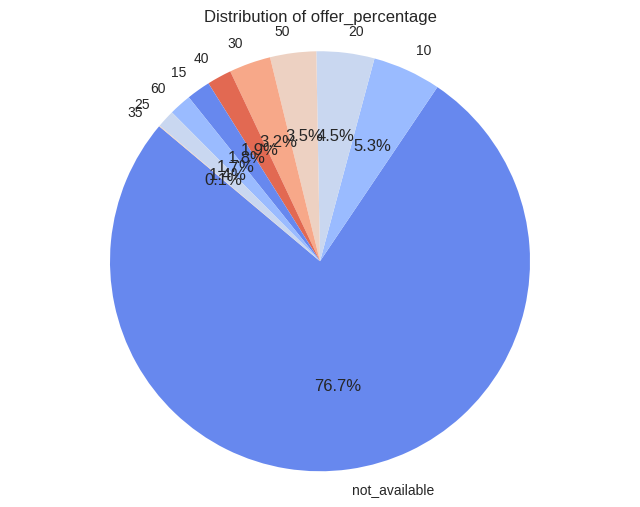

In [22]:
PlotPie(data)

# ***Data Preprocessing :***

In [23]:
# First : Dropping the Name because I think it will not contribute to the decision making 
data.drop(columns="hotel_name",inplace=True)

In [24]:
data["rating"].isna().sum()

0

In [25]:
data["rating"] = data["rating"].apply(lambda x: 1000 if isinstance(x, str) and "min" in x else x)
data["rating"] = data["rating"].astype(float)
median_rating = data["rating"][data["rating"] != 1000].median()
data["rating"] = data["rating"].replace(1000, median_rating)

In [26]:
data["time_minutes"].isna().sum()

343

In [27]:
def handle_object_range(val):
    if pd.isna(val):
        return np.nan
    if isinstance(val, str) and "-" in val:
        return val  
    try:
        return float(val) 
    except:
        return np.nan

data["time_minutes"] = data["time_minutes"].apply(handle_object_range)


def range_to_avg(val):
    if isinstance(val, str) and "-" in val:
        try:
            start, end = map(int, val.split("-"))
            return (start + end) / 2
        except:
            return np.nan
    return val

data["time_minutes"] = data["time_minutes"].apply(range_to_avg)


data["time_minutes"] = pd.to_numeric(data["time_minutes"], errors='coerce')

median_time = data["time_minutes"].median()
data["time_minutes"] = data["time_minutes"].fillna(median_time)


data["time_minutes"] = data["time_minutes"].round().astype(int)


In [28]:
data

,rating,time_minutes,food_type,location,offer_above,offer_percentage
0,4.5,27,"Burgers, Beverages, Cafe, Desserts",Kandivali East,75,30
1,4.2,30,"Burgers, Biryani, American, Snacks, Fast Food",Kandivali East,80,40
2,4.3,25,"Pizzas, Italian, Pastas, Desserts",Thakur Village,299,not_available
3,4.3,24,"Biryani, Kebabs, Hyderabadi, North Indian",Malad Kan East,100,50
4,4.6,22,"Snacks, Fast Food, Beverages, Jain",Kandivali East,120,60
...,...,...,...,...,...,...
1744,3.8,48,"North Indian, Chinese, Biryani, Tandoor",Kandivali west,700,20
1745,4.6,52,"Chinese, Biryani, Beverages",Malad Kan West,not_available,not_available
1746,4.0,48,"Indian, Lebanese, Mughlai, Chinese",Goregaon East,999,not_available
1747,4.1,43,"Desserts, Beverages",Malad West,not_available,not_available


In [29]:
data["location"].isna().sum()

0

In [30]:
LE = LabelEncoder()
data["location"] = LE.fit_transform(data["location"])

In [31]:
data["offer_above"].isna().sum()

0

In [32]:
# Replace "not_available" with NAN
data["offer_percentage"] = data["offer_percentage"].replace("not_available", np.nan)
data["offer_percentage"] = pd.to_numeric(data["offer_percentage"], errors='coerce')
median_offer = data["offer_percentage"].median()

# Fill NNNs with the median and convert to int
data["offer_percentage"] = data["offer_percentage"].fillna(median_offer).astype(int)


In [33]:
data

,rating,time_minutes,food_type,location,offer_above,offer_percentage
0,4.5,27,"Burgers, Beverages, Cafe, Desserts",69,75,30
1,4.2,30,"Burgers, Biryani, American, Snacks, Fast Food",69,80,40
2,4.3,25,"Pizzas, Italian, Pastas, Desserts",112,299,25
3,4.3,24,"Biryani, Kebabs, Hyderabadi, North Indian",89,100,50
4,4.6,22,"Snacks, Fast Food, Beverages, Jain",69,120,60
...,...,...,...,...,...,...
1744,3.8,48,"North Indian, Chinese, Biryani, Tandoor",76,700,20
1745,4.6,52,"Chinese, Biryani, Beverages",90,not_available,25
1746,4.0,48,"Indian, Lebanese, Mughlai, Chinese",55,999,25
1747,4.1,43,"Desserts, Beverages",91,not_available,25


In [34]:
# Dropping the Offer Perventage and offer above because the most of recorda are " Not Available"
data.drop(columns=["offer_percentage","offer_above"],inplace=True)

In [35]:
# Strip spaces and standardize entries
data["food_type"] = data["food_type"].apply(lambda x: str(x).strip())

# Calculate frequency of each unique value
frequency_map = data["food_type"].value_counts().to_dict()

data["food_type"] = data["food_type"].map(frequency_map)


In [36]:
data

,rating,time_minutes,food_type,location
0,4.5,27,4,69
1,4.2,30,2,69
2,4.3,25,2,112
3,4.3,24,2,89
4,4.6,22,2,69
...,...,...,...,...
1744,3.8,48,1,76
1745,4.6,52,1,90
1746,4.0,48,1,55
1747,4.1,43,8,91


In [37]:
data=data.drop_duplicates()

In [38]:
cols_to_scale = ["rating", "time_minutes", "location", "food_type"]
scaler = StandardScaler()
data[cols_to_scale] = scaler.fit_transform(data[cols_to_scale])

# ***Explaratory Data Analysis After Preprocessing :***

In [39]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1449 entries, 0 to 1748
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   rating        1449 non-null   float64
 1   time_minutes  1449 non-null   float64
 2   food_type     1449 non-null   float64
 3   location      1449 non-null   float64
dtypes: float64(4)
memory usage: 56.6 KB


In [40]:
data.duplicated().sum()

0

In [41]:
data.isna().sum()

rating          0
time_minutes    0
food_type       0
location        0
dtype: int64

In [42]:
data.columns

Index(['rating', 'time_minutes', 'food_type', 'location'], dtype='object')

In [43]:
GetObjectFeatures(data)

In [44]:
GetValuesCounts(data)

rating
 0.149913    279
 0.571299    179
 0.360606    165
-0.060780    147
 0.781992    113
-0.271472     81
 0.992684     69
-0.482165     61
-0.692858     58
-0.903551     43
 1.203377     41
-1.114244     25
 1.835456     24
-1.324936     22
-1.535629     21
-1.746322     20
 1.414070     16
-2.799786     11
 1.624763     10
-2.378400     10
-1.957015      9
-2.589093      6
-3.642557      6
-2.167708      5
-3.010479      5
-3.221172      5
-3.853250      4
-3.431864      4
-5.538792      4
-4.063943      3
-4.485328      1
-4.274635      1
-5.328099      1
Name: count, dtype: int64 

time_minutes
 0.052292    184
 0.142604     56
-0.038020     52
 0.323228     50
 0.684476     49
            ... 
 3.303523      1
 2.942275      1
 3.393835      1
 2.671339      1
 2.581027      1
Name: count, Length: 68, dtype: int64 

food_type
-0.531858    674
-0.485774    150
-0.439690     67
 2.832271     60
 3.062691     59
-0.347522     49
-0.393606     41
 0.113318     40
-0.209270     38
 

# ***Visualizations After Preprocessing :***

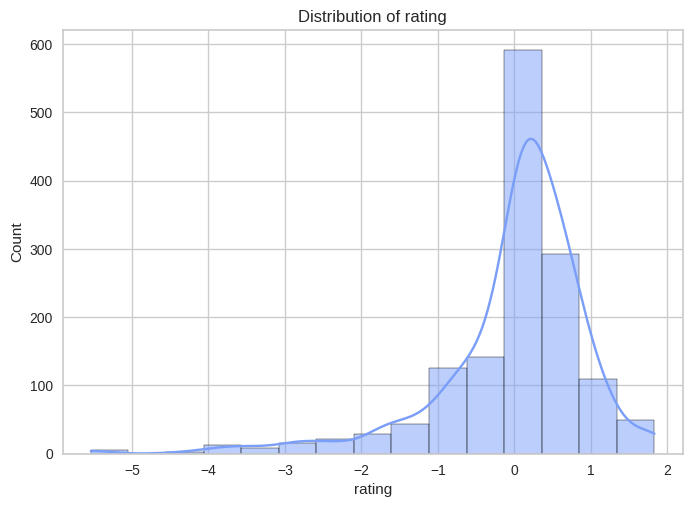

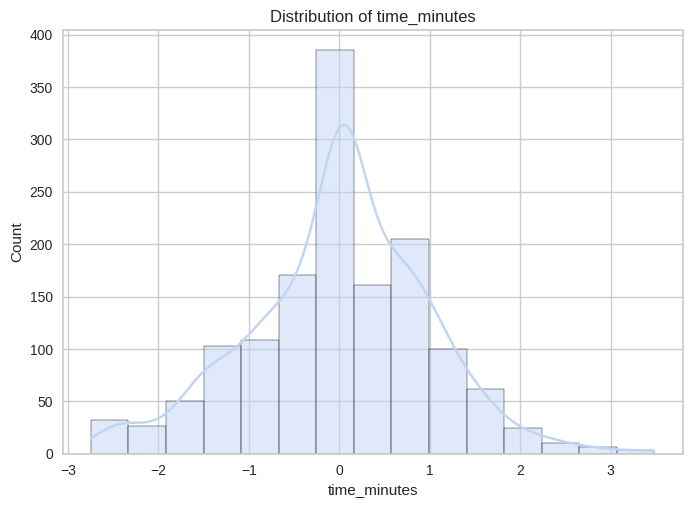

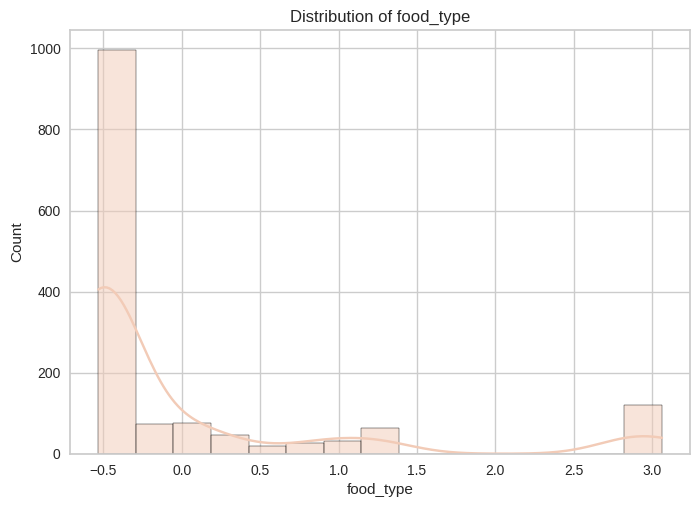

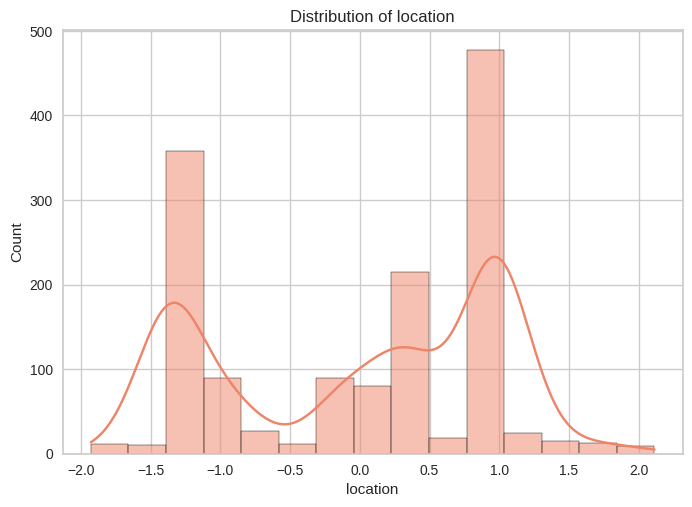

In [45]:
PDP(data)

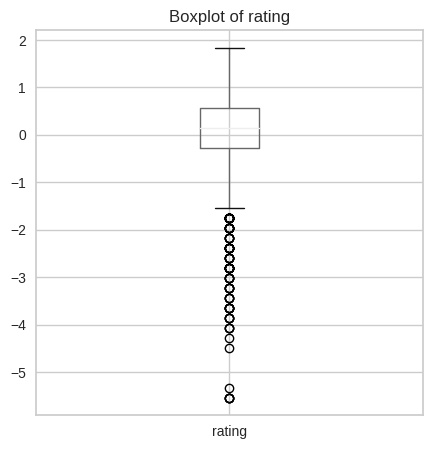

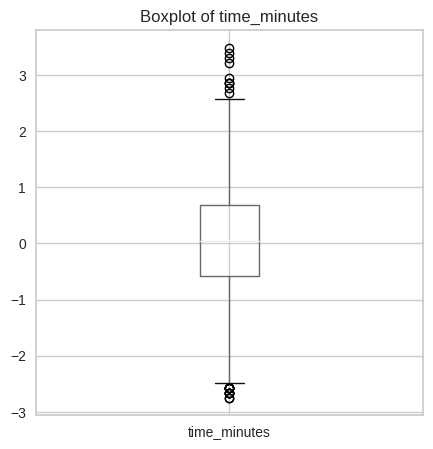

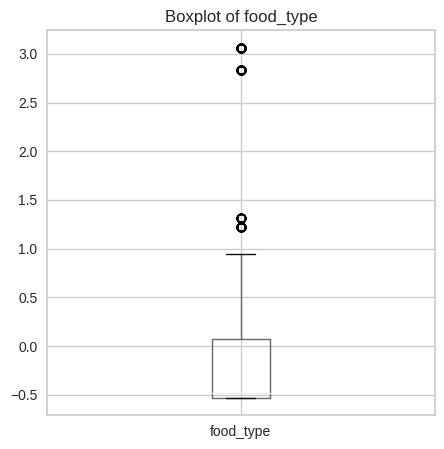

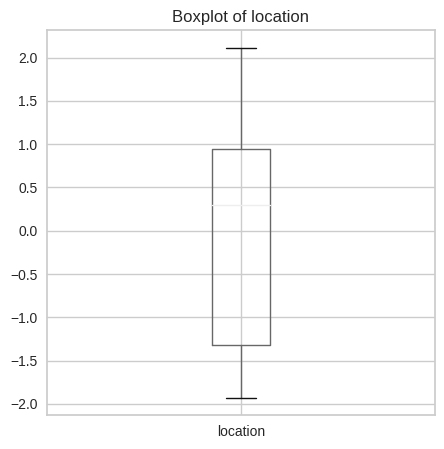

In [46]:
PBP(data)

# ***Dealing with Outliers :***

In [47]:
scaler = RobustScaler()
data[["rating"]] = scaler.fit_transform(data[["rating"]])

In [48]:
data[["time_minutes"]] = scaler.fit_transform(data[["time_minutes"]])

In [49]:
data[["food_type"]] = scaler.fit_transform(data[["food_type"]])

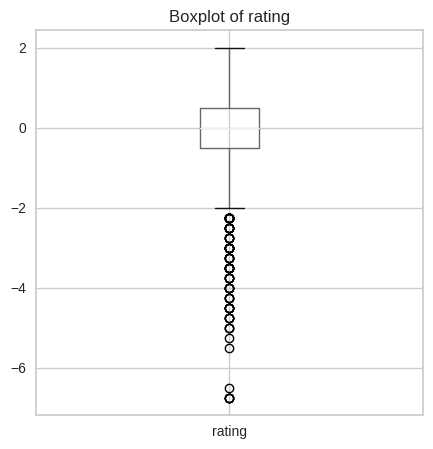

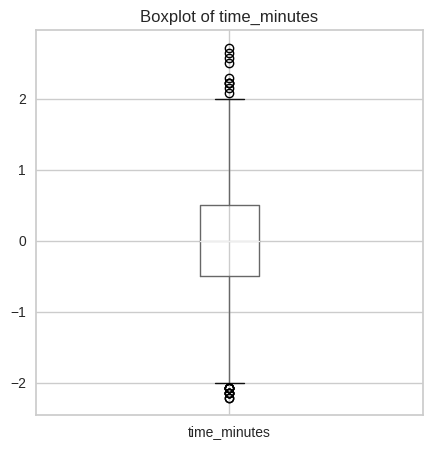

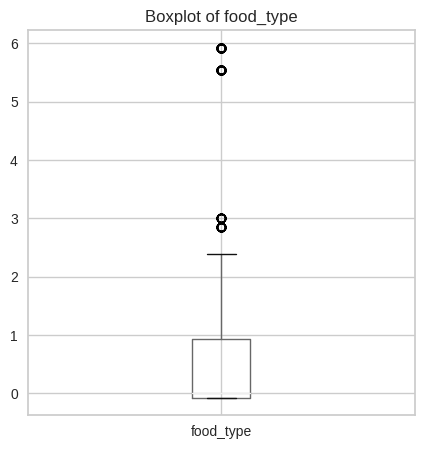

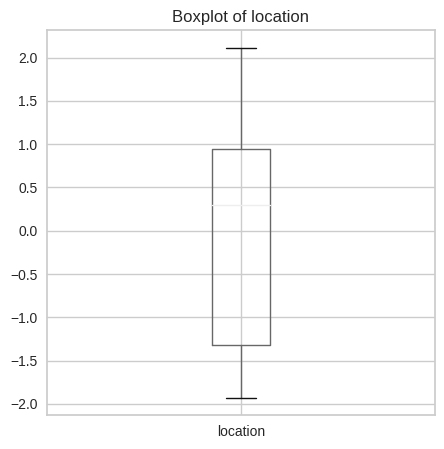

In [50]:
PBP(data)

 ##### it stills with the same problem without any changes even after applying the Robust Scaler

# ***Dealing with Skewness :***

In [51]:
pt = PowerTransformer(method='yeo-johnson')  
data["rating_transformed"] = pt.fit_transform(data[["rating"]])

In [52]:
data.drop(columns="rating",inplace=True)

In [53]:
pt = PowerTransformer(method='yeo-johnson')  
data["location"] = pt.fit_transform(data[["location"]])
data["food_type"] = pt.fit_transform(data[["food_type"]])

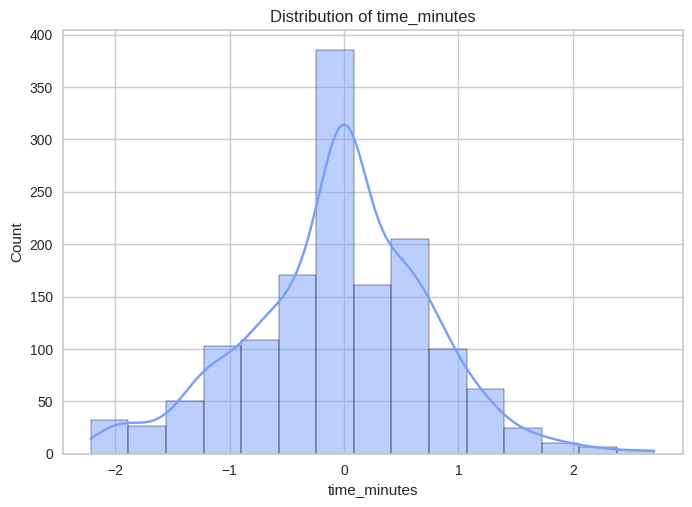

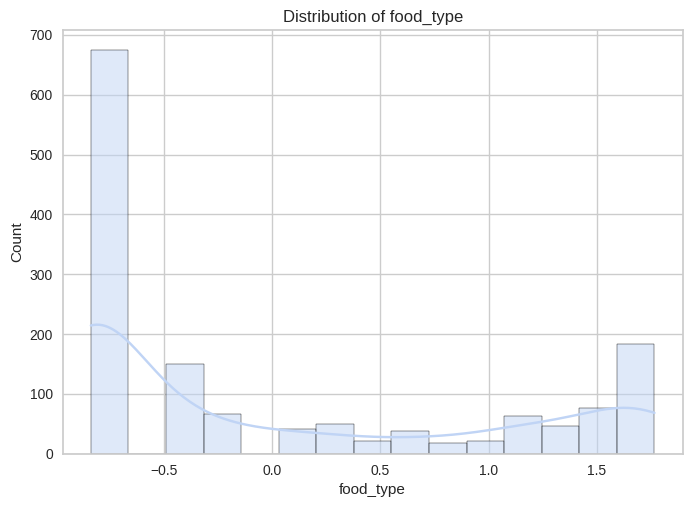

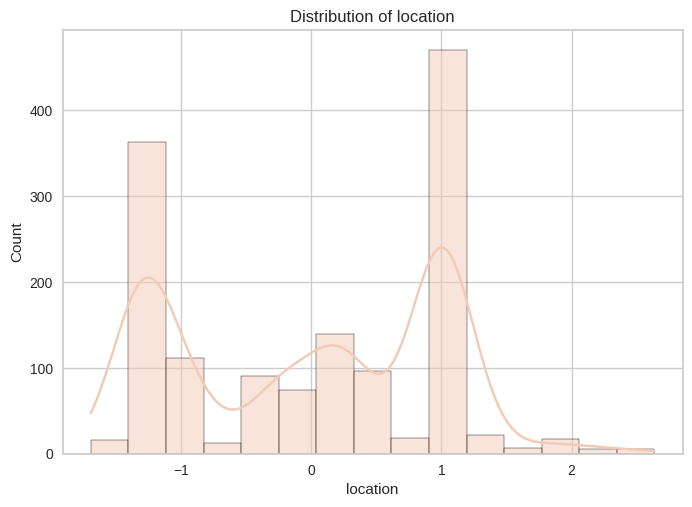

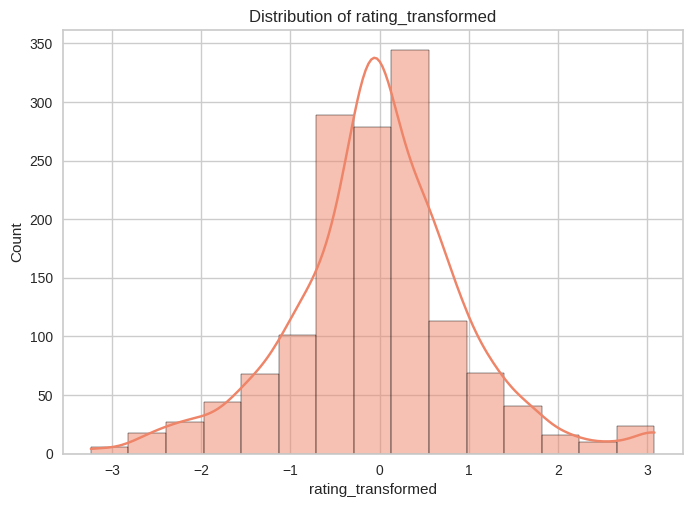

In [54]:
PDP(data)

# ***Key Points Of Data Pre-Processing :***

##### 1. Dropped the "hotel_name"column as it does not contribute to the model
##### 2. Cleaned the "rating" column by handling patterns and replacing missing values with the median
##### 3. Processed the "time_minutes" column by handling range patterns and filling missing values with the median
##### 4. Applied label encoding on the "location" column to convert it into numerical format
##### 5. Replaced"not_available" values with NAN in the "offer_percentage" column
##### 6. Dropped "offer_percentage" and "offer_above" columns due to a high percentage of unavailable data.
##### 7. Transformed the "food_type" column using frequency encoding to preserve information without increasing dimensionality.
##### 8. Removed duplicate records to ensure data quality.
##### 9. Applied standard scaling to the entire dataset for normalization.
##### 10. Used robust scaling on "food_type", "time_minutes","rating" to reduce the influence of outliers, but it was not effective.
##### 11. Applied power transformation on "food_type", "location", "rating" to handle skewness and improve data distribution, which gave satisfactory results.


# ***Applying K-Means Clustering :***

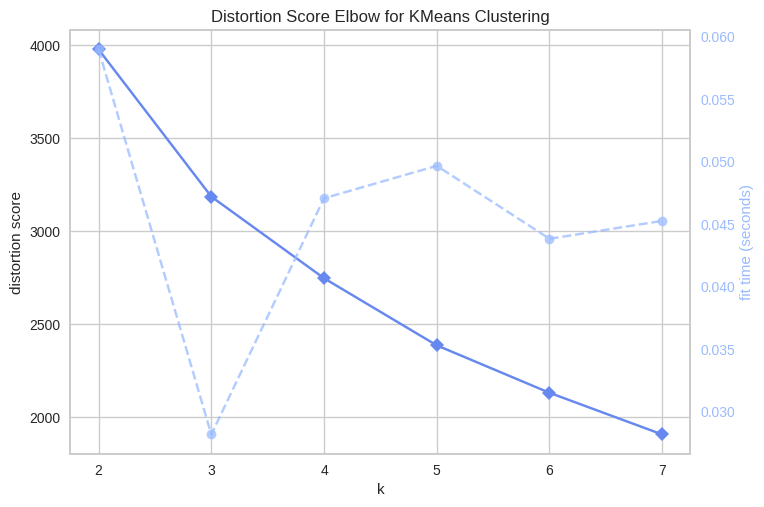

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [55]:
Elbow = KElbowVisualizer(KMeans(), k = 7)
Elbow.fit(data)
Elbow.show()

##### I was preparing it to make 2 clusters only and from these insights we should divide them to 2 clusters to avoid any overfitting 

In [56]:
scores = []
KRange = range(1, 7)

for k in KRange:
    KM = KMeans(n_clusters=k, random_state=42)
    KM.fit(data)
    scores.append(KM.inertia_)

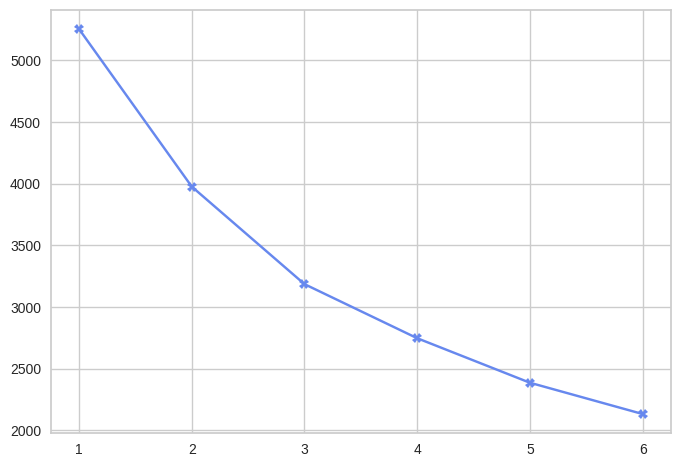

In [57]:
plt.plot(KRange, scores, marker = 'X')

(1.0, 5.0)

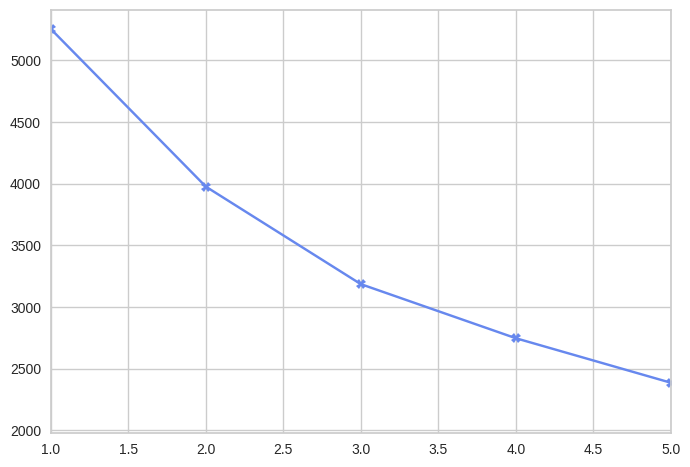

In [58]:
plt.plot(KRange, scores, marker = 'X')
plt.xlim(1,5,1)

(1.0, 4.0)

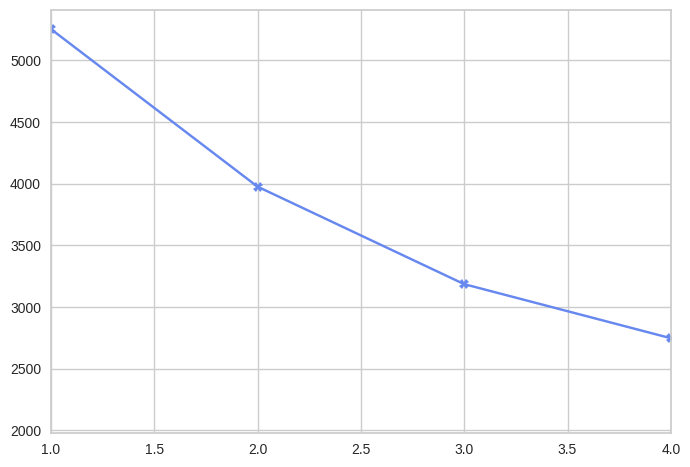

In [59]:
plt.plot(KRange, scores, marker = 'X')
plt.xlim(1,4,1)

##### Both 2 and 3 will be good choices as number of the clusters 

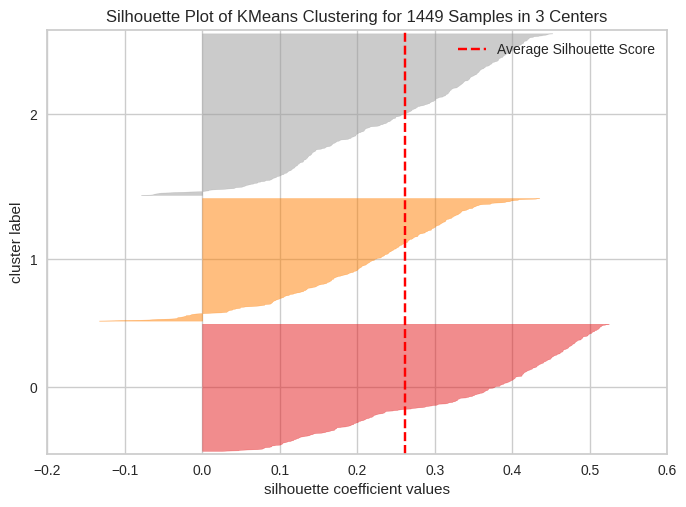

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 1449 Samples in 3 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [60]:
model = KMeans(3, random_state = 42)
visualizer = silhouette_visualizer(model,data)
visualizer.fit(data)
visualizer.show()

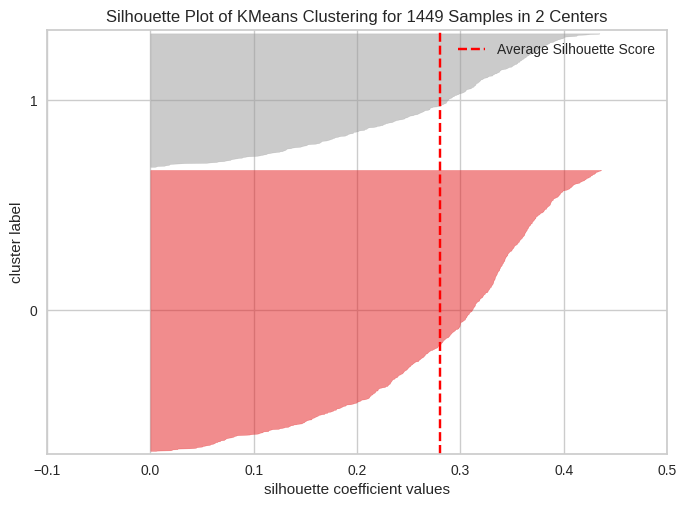

<Axes: title={'center': 'Silhouette Plot of KMeans Clustering for 1449 Samples in 2 Centers'}, xlabel='silhouette coefficient values', ylabel='cluster label'>

In [61]:
model = KMeans(2, random_state = 42)
visualizer = silhouette_visualizer(model,data)
visualizer.fit(data)
visualizer.show()

In [62]:
scores = []
silhouette_scores  = []

KRange = range(2,4)
for k in KRange:
    KM = KMeans(n_clusters = k)
    clusters = KM.fit_predict(data)
    scores.append(KM.inertia_)
    silhouette_scores.append(silhouette_score(data, clusters))
    
    print("k = ", k )
    print("silhouette score : %0.4f" % silhouette_score(data, clusters))

k =  2
silhouette score : 0.2800
k =  3
silhouette score : 0.2619


# ***Final Number Of Clusters :***

### In my opinion I think the best number of clusters we can work on is 3 because it makes more balance between classes and that's clear from the Silhoutte Plots, and it is also has good Silhoutte Score and for sure the Elbow plots was confirming the 3 clusters more than 2 

In [63]:
KM = KMeans(n_clusters = 3,random_state = 42)
KM.fit(data)
predictedClusters = KM.predict(data)

In [64]:
KM.cluster_centers_

array([[ 0.03140944, -0.58942352, -0.9975375 , -0.08556766],
       [-0.07671958,  1.42113246, -0.02527573, -0.01638761],
       [-0.07180517, -0.61488134,  0.8045974 ,  0.07981329]])

In [65]:
data["Recommendation Clusters"]=predictedClusters

In [66]:
data

,time_minutes,food_type,location,rating_transformed,Recommendation Clusters
0,-1.142857,0.045283,0.182902,0.886500,2
1,-0.928571,-0.480401,0.182902,-0.052220,2
2,-1.285714,-0.480401,2.001491,0.224702,2
3,-1.357143,-0.480401,0.968378,0.224702,2
4,-1.500000,-0.480401,0.182902,1.266942,2
...,...,...,...,...,...
1743,2.000000,0.241572,-0.128444,-1.030052,0
1744,0.357143,-0.836980,0.444229,-0.868721,2
1746,0.357143,-0.836980,-0.288298,-0.503656,0
1747,0.000000,0.665637,1.053117,-0.292064,1


Text(0.5, 1.0, 'Relation between Ratings and Delivery time by Minutes: ')

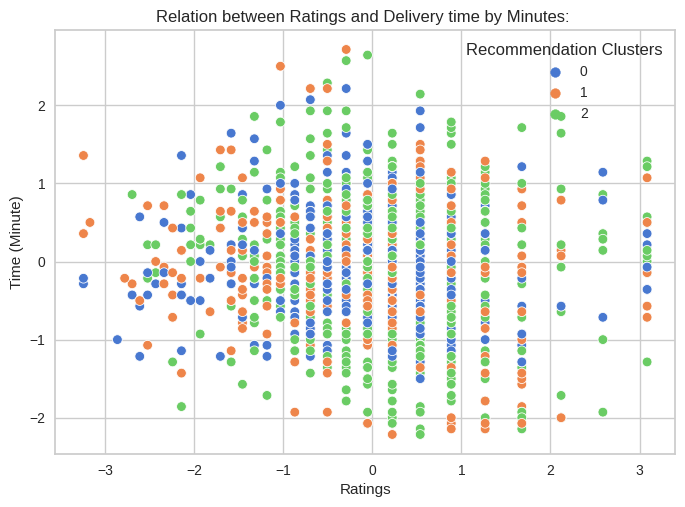

In [67]:
sns.scatterplot(x=data["rating_transformed"],y=data["time_minutes"],hue=data["Recommendation Clusters"],palette='muted')
plt.xlabel("Ratings")
plt.ylabel("Time (Minute)")
plt .title("Relation between Ratings and Delivery time by Minutes: ")

In [68]:
data.to_csv("prepared data for classification (Swiggy Dataset) - 3 clusters.csv", index=False)

# ***Applying Classification Models (to classify the recommendation clusters) :***

# ***Splitting the dataset :***

In [69]:
X = data.drop("Recommendation Clusters", axis=1)
Y = data["Recommendation Clusters"]

Ftrain, Ftest, Gtrain, Gtest = train_test_split(X,Y, test_size=0.2, random_state=99)

In [70]:
Ftrain

,time_minutes,food_type,location,rating_transformed
1040,0.000000,1.765674,-1.257875,0.224702
319,0.785714,-0.836980,1.010618,-0.503656
1015,0.000000,1.121866,0.968378,-0.052220
1667,-0.214286,0.546050,0.330313,-0.694317
1575,0.000000,-0.480401,-0.061843,-0.052220
...,...,...,...,...
1192,0.571429,-0.836980,-1.257875,-0.292064
1324,0.000000,1.567359,-1.305453,-0.052220
1359,0.000000,1.631441,0.968378,-0.052220
1159,1.142857,1.757934,0.968378,0.886500


In [71]:
Ftest

,time_minutes,food_type,location,rating_transformed
1354,-1.214286,-0.836980,0.968378,0.886500
629,-0.285714,1.765674,-1.257875,0.224702
1039,1.071429,1.765674,0.926401,0.538434
489,-0.714286,1.765674,-1.257875,-0.052220
1204,0.000000,0.045283,1.269421,-0.052220
...,...,...,...,...
476,-1.142857,-0.191330,0.182902,-0.868721
1629,0.000000,1.465813,-0.128444,-0.052220
1100,-1.714286,0.665637,0.968378,2.118794
115,-0.928571,-0.836980,-1.305453,-0.868721


In [72]:
Gtrain

1040    1
319     2
1015    1
1667    1
1575    2
       ..
1192    0
1324    1
1359    1
1159    1
686     2
Name: Recommendation Clusters, Length: 1159, dtype: int32

In [73]:
Gtest

1354    2
629     1
1039    1
489     1
1204    2
       ..
476     2
1629    1
1100    2
115     0
1066    1
Name: Recommendation Clusters, Length: 290, dtype: int32

# ***Training And Evaluation :***

In [74]:
models = {
        'Logistic Regression': LogisticRegression(),
        'Random Forest': RandomForestClassifier(n_estimators=5, random_state=42),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=10, learning_rate=0.2, random_state=42),
        'Decision Tree': DecisionTreeClassifier(random_state=42)}


Evaluating Logistic Regression...

Logistic Regression Accuracy: 0.9845
[[361   0   7]
 [  4 342   5]
 [  2   0 438]]


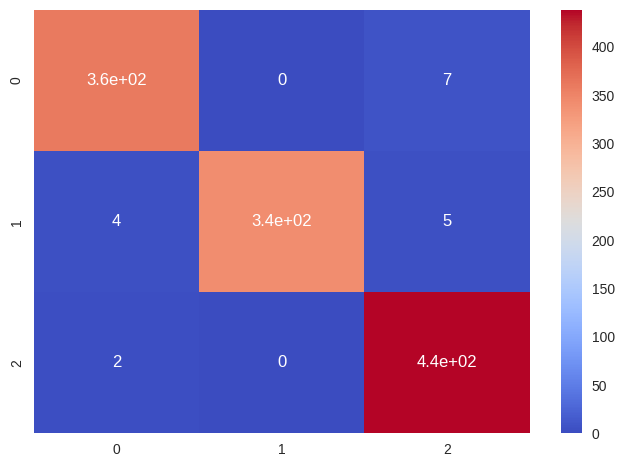

Precision: 0.9847
Recall: 0.9845
F1-Score: 0.9845
ROC-AUC: 0.9997

Classification Report for Logistic Regression:

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       368
           1       1.00      0.97      0.99       351
           2       0.97      1.00      0.98       440

    accuracy                           0.98      1159
   macro avg       0.99      0.98      0.98      1159
weighted avg       0.98      0.98      0.98      1159


------------------------------------------------------------


Evaluating Random Forest...

Random Forest Accuracy: 0.9741
[[365   1   2]
 [  5 332  14]
 [  7   1 432]]


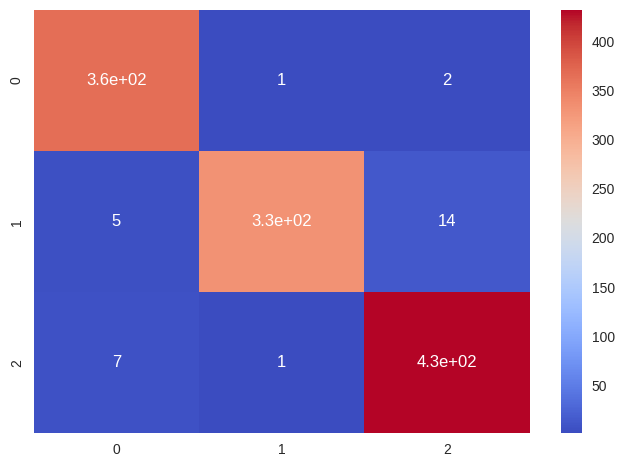

Precision: 0.9745
Recall: 0.9741
F1-Score: 0.9741
ROC-AUC: 0.9980

Classification Report for Random Forest:

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       368
           1       0.99      0.95      0.97       351
           2       0.96      0.98      0.97       440

    accuracy                           0.97      1159
   macro avg       0.98      0.97      0.97      1159
weighted avg       0.97      0.97      0.97      1159


------------------------------------------------------------


Evaluating Gradient Boosting...

Gradient Boosting Accuracy: 0.9741
[[364   1   3]
 [  5 325  21]
 [  0   0 440]]


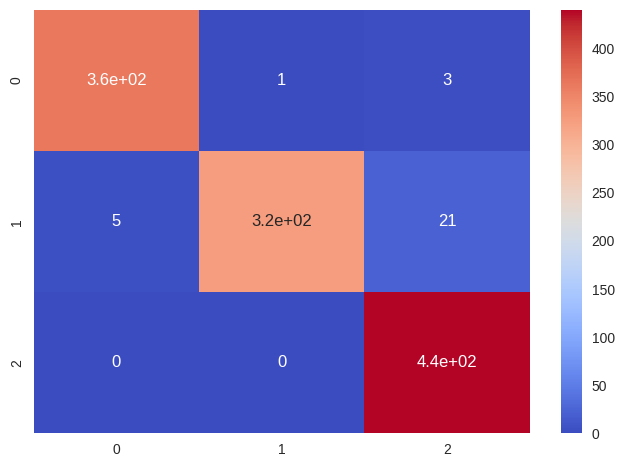

Precision: 0.9751
Recall: 0.9741
F1-Score: 0.9740
ROC-AUC: 0.9985

Classification Report for Gradient Boosting:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       368
           1       1.00      0.93      0.96       351
           2       0.95      1.00      0.97       440

    accuracy                           0.97      1159
   macro avg       0.98      0.97      0.97      1159
weighted avg       0.98      0.97      0.97      1159


------------------------------------------------------------


Evaluating Decision Tree...

Decision Tree Accuracy: 0.9750
[[356   0  12]
 [  8 338   5]
 [  1   3 436]]


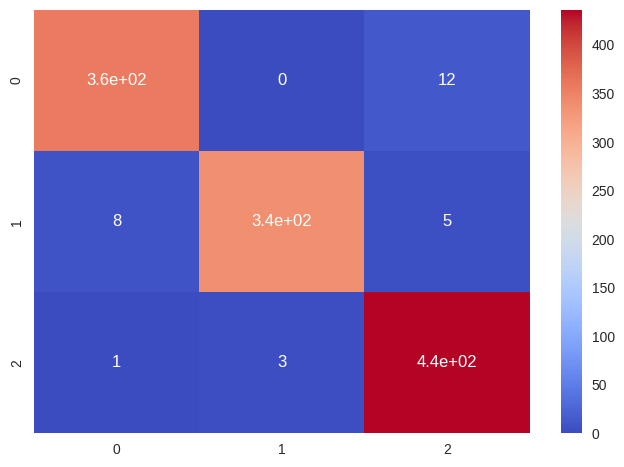

Precision: 0.9753
Recall: 0.9750
F1-Score: 0.9750
ROC-AUC: 0.9803

Classification Report for Decision Tree:

              precision    recall  f1-score   support

           0       0.98      0.97      0.97       368
           1       0.99      0.96      0.98       351
           2       0.96      0.99      0.98       440

    accuracy                           0.97      1159
   macro avg       0.98      0.97      0.97      1159
weighted avg       0.98      0.97      0.97      1159


------------------------------------------------------------



In [75]:
TrainEvaluateModel(Ftest,Gtest,Ftrain,Gtrain,models)

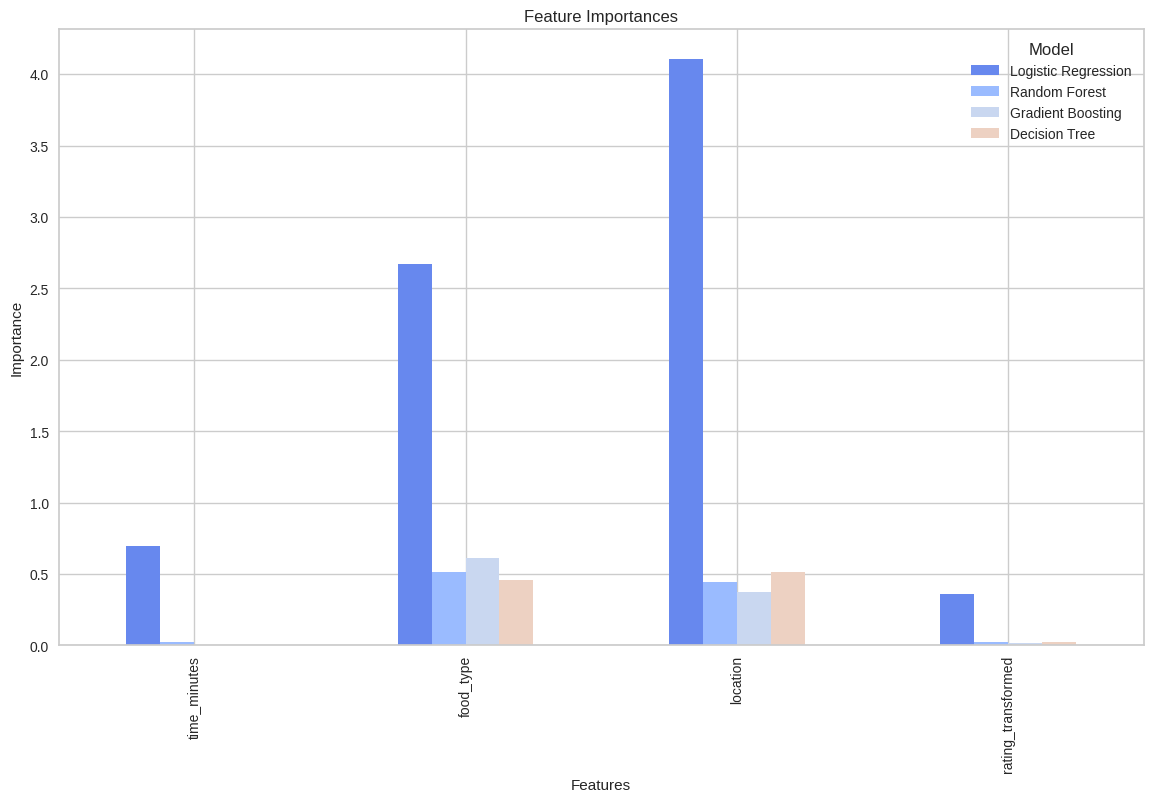

In [76]:
PlotFeaturesImportance(X,Y,models)

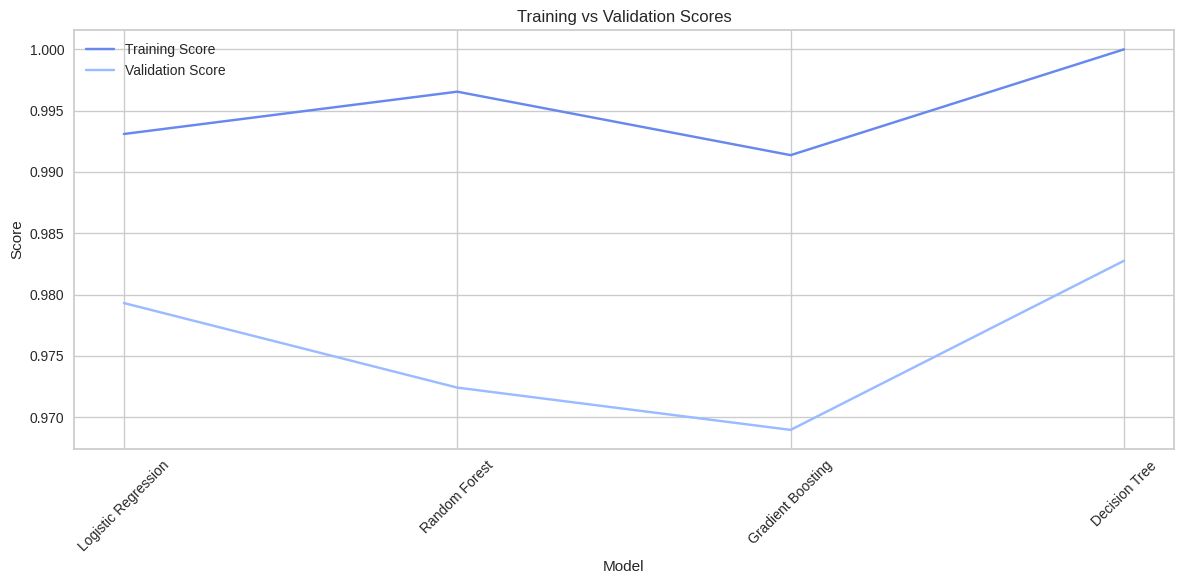

In [77]:
PlotOverfitting(models,Ftrain,Ftest,Gtrain,Gtest)

# ***Choosing the final model :***

### In my opinion the best model is logistic regression model then decision trees model because they have high accuracies and also good evaluations with different matrcies like precision, recall and F1 score too . and gives small differnce between the validation and training set


# ***Saving the final models :***

In [78]:
SaveModels(models)

Model 'Logistic Regression' saved as 'Models - Logistic Regression.sav'.
Model 'Random Forest' saved as 'Models - Random Forest.sav'.
Model 'Gradient Boosting' saved as 'Models - Gradient Boosting.sav'.
Model 'Decision Tree' saved as 'Models - Decision Tree.sav'.
